IMPORTING REQUIRED LIBRARIES

In [20]:
import pubchempy as pcp
from rdkit import Chem
from rdkit.Chem import Draw,Descriptors
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

CREATING A FUNCTION,WHICH INCLUDES 3 SUB FUNCTIONS GIVING 3 OUTPUTS AND MAIN WORKFLOW

In [21]:
"""MAIN FUNCTION"""
def analyze_by_lipinskirule(chemical_name):

  print(f"Analyzing Chemical: {chemical_name}\n"+"="*35)

  """1ST SUBFUNCTION:FETCHING SMILES FROM PUBCHEM"""
  def get_smiles(name):
    try:
      name=name.lower()
      compounds=pcp.get_compounds(name, 'name')
      """USING CONNECTIVITY SMILES TO AVOID IRRITATING WARNING FROM PUBCHEMPY"""
      if compounds:
        return compounds[0].connectivity_smiles
      else:
        print(f"No compounds found for name: {name}")
        return None
    except:
      return None

  """2ND SUBFUNCTION:DRAW MOLECULE"""
  def draw_molecule(smiles,title):
    mol=Chem.MolFromSmiles(smiles)
    if mol is None:
      print(f"Invalid SMILES string: {smiles}")
      return
    img=Draw.MolToImage(mol)
    plt.figure(figsize=(5,5))
    plt.title(title,fontsize=14,fontweight='bold')
    plt.imshow(img)
    plt.axis('off')
    plt.show()

  """3RD SUBFUNCTION:CHECK LIPINSKI RULE OF 5"""
  def check_lipinski(smiles):
    if not smiles:
      print("Invalid SMILES string")
      return

    mol=Chem.MolFromSmiles(smiles)
    if mol is None:
      print("Failed to parse the molecule from rdkit")
      return

    mw=Descriptors.MolWt(mol)
    logp=Descriptors.MolLogP(mol)
    hbd=Descriptors.NumHDonors(mol)
    hba=Descriptors.NumHAcceptors(mol)

    mw_pass= mw <=500
    logp_pass= logp<=5
    hbd_pass= hbd <=5
    hba_pass= hba <=10

    violations=sum([not mw_pass, not logp_pass, not hbd_pass, not hba_pass])
    """LIPINSKI RULE OF 5 ALLOWS ATMOST ONE VIOLATION"""
    is_candidate_valid = violations <=1

    print("\n---- Lipinski Analysis ----")
    print(f"Molecular Weight (MW): {mw:.2f}Da (Rule: <= 500)| {'PASS' if mw_pass else 'FAIL'}")
    print(f"LogP: {logp:.2f} (Rule: <= 5)| {'PASS' if logp_pass else 'FAIL'}")
    print(f"Number of Hydrogen Bond Donors (HBD): {hbd} (Rule: <= 5)| {'PASS' if hbd_pass else 'FAIL'}")
    print(f"Number of Hydrogen Bond Acceptors (HBA): {hba} (Rule: <= 10)| {'PASS' if hba_pass else 'FAIL'}")
    print(f"Total Violations: {violations} (Rule: <= 1)")

    if is_candidate_valid:
      print("\nResult: This is a Potential drug candidate")
    else:
      print("\nResult: This is not a potential drug candidate")

  """MAIN WORKFLOW EXEECUTION"""
  smiles=get_smiles(chemical_name)
  if smiles:
      print(f"Found Smiles: {smiles}\n")
      draw_molecule(smiles,chemical_name)
      check_lipinski(smiles)
  else:
      print("Analysis Failed due to missing Chemical Data")

Analyzing Chemical: METFORMIN
Found Smiles: CN(C)C(=N)N=C(N)N



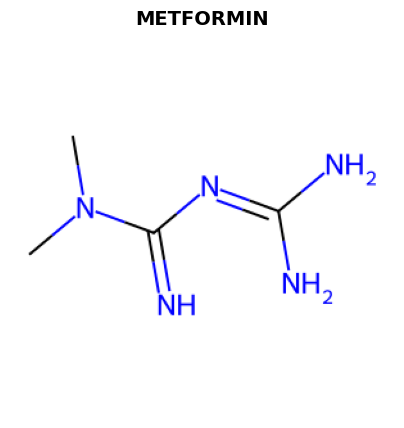


---- Lipinski Analysis ----
Molecular Weight (MW): 129.17Da (Rule: <= 500)| PASS
LogP: -1.24 (Rule: <= 5)| PASS
Number of Hydrogen Bond Donors (HBD): 3 (Rule: <= 5)| PASS
Number of Hydrogen Bond Acceptors (HBA): 1 (Rule: <= 10)| PASS
Total Violations: 0 (Rule: <= 1)

Result: This is a Potential drug candidate


In [22]:
analyze_by_lipinskirule('METFORMIN')

Analyzing Chemical: heroin
Found Smiles: CC(=O)OC1C=CC2C3CC4=C5C2(C1OC5=C(C=C4)OC(=O)C)CCN3C



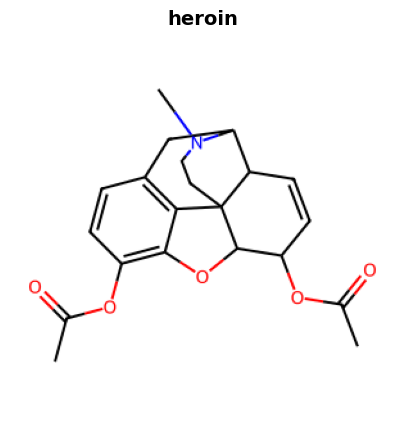


---- Lipinski Analysis ----
Molecular Weight (MW): 369.42Da (Rule: <= 500)| PASS
LogP: 1.99 (Rule: <= 5)| PASS
Number of Hydrogen Bond Donors (HBD): 0 (Rule: <= 5)| PASS
Number of Hydrogen Bond Acceptors (HBA): 6 (Rule: <= 10)| PASS
Total Violations: 0 (Rule: <= 1)

Result: This is a Potential drug candidate


In [23]:
analyze_by_lipinskirule('heroin')